<a href="https://colab.research.google.com/github/ASHIK-77/ML-LAB/blob/main/EXP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error,r2_score


In [2]:
url="https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df=pd.read_csv(url)
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
x=df[['displacement']]
y=df['mpg']

print("Missing values in",x.isnull().sum())
print("Missing values in mpg:",y.isnull().sum())

Missing values in displacement    0
dtype: int64
Missing values in mpg: 0


In [4]:
data = df[['displacement','mpg']].dropna()
x=data[['displacement']]
y=data['mpg']
print('feature:')
print(x.head())
print("\nTarget:")
print(y.head())

feature:
   displacement
0         307.0
1         350.0
2         318.0
3         304.0
4         302.0

Target:
0    18.0
1    15.0
2    18.0
3    16.0
4    17.0
Name: mpg, dtype: float64


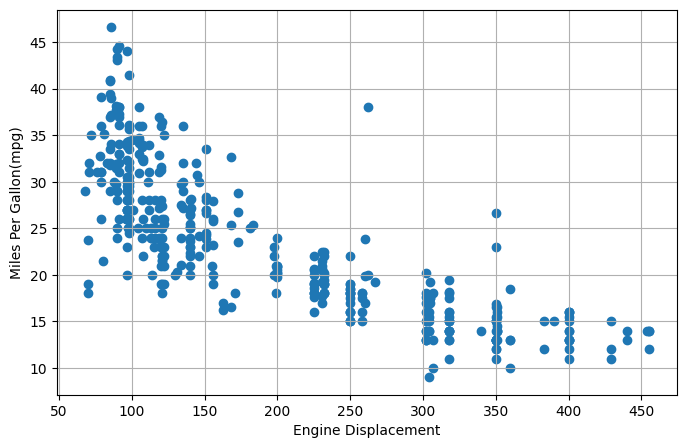

In [8]:
plt.figure(figsize=(8,5))
plt.scatter(x,y)
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon(mpg)")
plt.grid(True)
plt.show()

In [9]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)
print("training samples:",len(x_train))
print("testing samples: ",len(x_test))

training samples: 318
testing samples:  80


In [11]:
linear_model=LinearRegression()
linear_model.fit(x_train,y_train)
y_pred_linear = linear_model.predict(x_test)
mse_linear = mean_squared_error(y_test,y_pred_linear)
r2_linear=r2_score(y_test,y_pred_linear)
print("Linear Regression Results")
print("MSE: ",mse_linear)
print("R-squared: ",r2_linear)

Linear Regression Results
MSE:  18.102543998358946
R-squared:  0.6633114869465596


In [13]:
results=[]
polynomial_models={}
results.append({
    'Model':'Linear Regression',
    'Degree':1,
    "MSE":mse_linear,
    "R-squared":r2_linear
})

In [14]:
for degree in range(2,6):
  poly=PolynomialFeatures(degree=degree)
  x_train_poly=poly.fit_transform(x_train)
  x_test_poly=poly.transform(x_test)
  poly_model=LinearRegression()
  poly_model.fit(x_train_poly,y_train)

  y_pred_poly=poly_model.predict(x_test_poly)

  mse=mean_squared_error(y_test,y_pred_poly)

  r2=r2_score(y_test,y_pred_poly)

  results.append({
      'Model':'Polynomial Regression',
      'Degree':degree,
      'MSE':mse,
      'R-squared':r2
  })

  polynomial_models[degree]={
      'poly':poly,
      'model':poly_model
  }





In [16]:
x_plot=pd.DataFrame({
    'displacement':np.linspace(
        x['displacement'].min(),
        x['displacement'].max(),
        300
    )
})

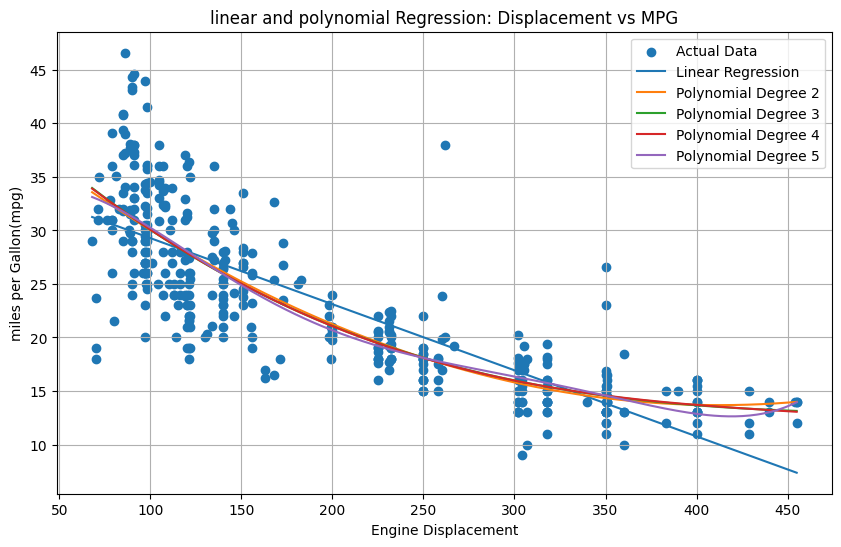

In [17]:
plt.figure(figsize=(10,6))
plt.scatter(
    x['displacement'],
    y,
    label='Actual Data'
)
y_plot_linear = linear_model.predict(x_plot)
plt.plot(
    x_plot['displacement'],
    y_plot_linear,
    label='Linear Regression'
)
for degree in range(2,6):
  poly = polynomial_models[degree]['poly']
  poly_model=polynomial_models[degree]['model']

  x_plot_poly = poly.transform(x_plot)
  y_plot_poly=poly_model.predict(x_plot_poly)
  plt.plot(
      x_plot['displacement'],
      y_plot_poly,
      label=f'Polynomial Degree {degree}'
  )
plt.xlabel("Engine Displacement")
plt.ylabel("miles per Gallon(mpg)")
plt.title("linear and polynomial Regression: Displacement vs MPG")
plt.legend()
plt.grid(True)
plt.show()

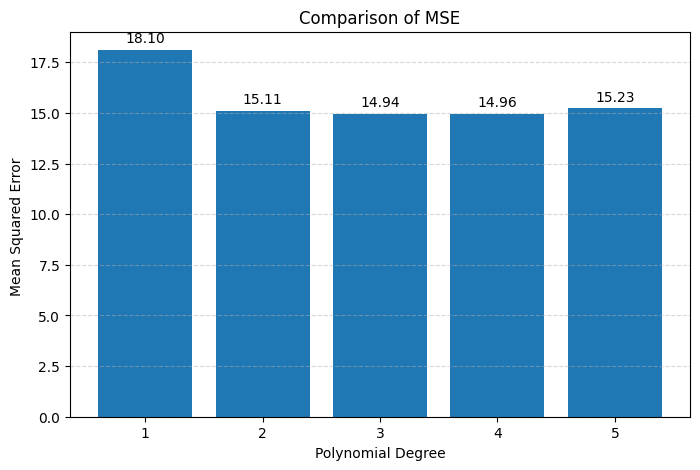

In [19]:
results_df=pd.DataFrame(results)
plt.figure(figsize=(8,5))
bars=plt.bar(
    results_df['Degree'].astype(str),
    results_df['MSE']
)
plt.bar_label(bars,fmt='%.2f',padding=3)
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error ")
plt.title("Comparison of MSE")
plt.grid(axis = 'y',linestyle='--',alpha=0.5)
plt.show()

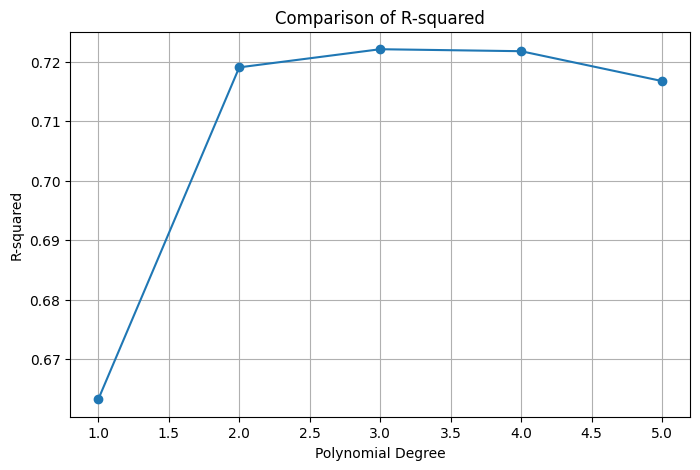

In [20]:
plt.figure(figsize=(8,5))
plt.plot(
    results_df['Degree'],
    results_df['R-squared'],
    marker='o'
)
plt.xlabel("Polynomial Degree")
plt.ylabel("R-squared")
plt.title("Comparison of R-squared")
plt.grid(True)
plt.show()